# Lung Nodule Detection in CT: Regularized, Cross-Validated Faster R-CNN v2 and YOLOv8 with Ensemble + TTA
Kaggle: enable **GPU** and **Internet**. All tuning is done with 5-fold CV on train+val (102 images). The 18-image **test set is used once, at the very end**.

Anti-overfitting choices: fixed epochs with no checkpoint picking, weight decay, augmentation, EMA weights (Faster R-CNN), early stopping (YOLO), threshold tuned on out-of-fold predictions, and a fold-model ensemble.

## 1. Setup, data and folds

In [1]:
import gc, os, glob, math, json, random, shutil, numpy as np, pandas as pd, torch, matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image, ImageOps
from sklearn.model_selection import StratifiedKFold
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.ops import box_iou
import torchvision.transforms.functional as TF
get_ipython().system("pip -q install ultralytics torchmetrics pycocotools ensemble-boxes")
from torchmetrics.detection import MeanAveragePrecision
from ensemble_boxes import weighted_boxes_fusion
from ultralytics import YOLO

SEED=42; K=5
SINGLE=True      # True: one class "nodule" (matches the assignment). False: keep class 0 / class 1 separate.
def seed_all(s): random.seed(s); np.random.seed(s); torch.manual_seed(s)
seed_all(SEED); dev=torch.device("cuda" if torch.cuda.is_available() else "cpu"); print(dev)

SRC=os.path.dirname(glob.glob("/kaggle/input/**/dataset_info.json",recursive=True)[0]); ROOT="/kaggle/working/data"
if not os.path.exists(ROOT): shutil.copytree(SRC,ROOT)
print(open(f"{ROOT}/dataset_info.json").read()[:500])
def items(sp): return [(p,f"{ROOT}/{sp}/labels/"+os.path.basename(p)[:-4]+".txt") for p in sorted(glob.glob(f"{ROOT}/{sp}/images/*.jpg"))]
pool=items("train")+items("val"); test_items=items("test")
strat=[int(any(l.split()[0]=="1" for l in open(lp).read().strip().splitlines())) for _,lp in pool]
folds=list(StratifiedKFold(K,shuffle=True,random_state=SEED).split(np.zeros(len(pool)),strat)); print(len(pool),len(test_items))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
cuda
{
  "seed": 42,
  "source_to_model_label": {
    "0": 1,
    "1": 2
  },
  "background_label": 0,
  "model_num_classes": 3,
  "annotation_format": "class_id x_center y_center box_width box_height",
  "images_per_split": {
    "train": 84,
    "val": 18,
    "test": 18
  },
  "boxes_per_split": {
    "train": 87,
    "val": 18,
    "test": 19
  },
  "boxes_per_source_class": {
    "0": 85,
    "1": 39
  }
}
102 18


## 2. Dataset, model builder, metrics and inference helpers

In [2]:
class DS(torch.utils.data.Dataset):
    def __init__(self, its, train=False): self.its=its; self.train=train
    def __len__(self): return len(self.its)
    def __getitem__(self,i):
        p,lp=self.its[i]; img=Image.open(p).convert("RGB"); W,H=img.size; b,l=[],[]
        for ln in open(lp).read().strip().splitlines():
            c,x,y,w,h=map(float,ln.split()); b.append([(x-w/2)*W,(y-h/2)*H,(x+w/2)*W,(y+h/2)*H]); l.append(1 if SINGLE else int(c)+1)
        t=TF.to_tensor(img); b=torch.tensor(b,dtype=torch.float32); l=torch.tensor(l,dtype=torch.int64)
        if self.train:
            if random.random()<0.5: t=t.flip(-1); b[:,[0,2]]=W-b[:,[2,0]]
            if random.random()<0.5: t=t.flip(-2); b[:,[1,3]]=H-b[:,[3,1]]
            if random.random()<0.5:                       # crop-zoom, every box stays inside
                s=random.uniform(0.7,1.0); cw,ch=int(W*s),int(H*s)
                xlo,xhi=max(0,b[:,2].max().item()-cw),min(b[:,0].min().item(),W-cw); ylo,yhi=max(0,b[:,3].max().item()-ch),min(b[:,1].min().item(),H-ch)
                if xlo<=xhi and ylo<=yhi:
                    x0,y0=int(math.ceil(random.uniform(xlo,xhi))),int(math.ceil(random.uniform(ylo,yhi)))
                    t=TF.resized_crop(t,y0,x0,ch,cw,[H,W],antialias=True)
                    b=((b-torch.tensor([x0,y0,x0,y0]))*torch.tensor([W/cw,H/ch,W/cw,H/ch])).clamp(0,W)
            t=TF.adjust_brightness(t,random.uniform(0.8,1.2)); t=TF.adjust_contrast(t,random.uniform(0.8,1.2)).clamp(0,1)
        return t,{"boxes":b,"labels":l},p
coll=lambda b: tuple(zip(*b))
DL=lambda its,tr: torch.utils.data.DataLoader(DS(its,tr),batch_size=4,shuffle=tr,collate_fn=coll)

def build_frcnn():
    m=fasterrcnn_resnet50_fpn_v2(weights=FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT,min_size=800,max_size=800)
    m.rpn.anchor_generator=AnchorGenerator(((16,),(32,),(64,),(128,),(256,)),((0.5,1.0,2.0),)*5)
    m.roi_heads.box_predictor=FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features,2 if SINGLE else 3)
    m.roi_heads.detections_per_img=50; m.roi_heads.score_thresh=0.001
    return m.to(dev)

# ---- metrics
def mAP(res):
    mp=MeanAveragePrecision(iou_type="bbox"); mp.update([r[0] for r in res],[r[1] for r in res]); m=mp.compute(); return float(m["map_50"]),float(m["map"])
def prf(res,thr):
    tp=fp=fn=0
    for p,t in res:
        k=p["scores"]>=thr; used=set()
        for b,l in zip(p["boxes"][k],p["labels"][k]):
            if len(t["boxes"]):
                iou=box_iou(b[None],t["boxes"])[0]; j=int(iou.argmax())
                if iou[j]>=0.5 and t["labels"][j]==l and j not in used: tp+=1; used.add(j); continue
            fp+=1
        fn+=len(t["boxes"])-len(used)
    P=tp/max(tp+fp,1); R=tp/max(tp+fn,1); return P,R,2*P*R/max(P+R,1e-9)
def best_thr(res): return float(max(np.arange(0.05,0.91,0.05),key=lambda th: prf(res,th)[2]))

# ---- raw predictions (+ horizontal-flip TTA) and fusion
@torch.no_grad()
def raw_frcnn(m,img,flip=False):
    W,H=img.size; t=TF.to_tensor(ImageOps.mirror(img) if flip else img).to(dev); p=m.eval()([t])[0]; b=p["boxes"].cpu().numpy().copy()
    if flip: b[:,[0,2]]=W-b[:,[2,0]]
    return b,p["scores"].cpu().numpy(),p["labels"].cpu().numpy()
def raw_yolo(m,img,imgsz,flip=False):
    W,H=img.size; r=m.predict(ImageOps.mirror(img) if flip else img,conf=0.001,imgsz=imgsz,verbose=False)[0].boxes; b=r.xyxy.cpu().numpy().copy()
    if flip: b[:,[0,2]]=W-b[:,[2,0]]
    lab=np.ones(len(b),int) if SINGLE else r.cls.cpu().numpy().astype(int)+1
    return b,r.conf.cpu().numpy(),lab
def to_dict(b,s,l): return {"boxes":torch.tensor(np.asarray(b),dtype=torch.float32).reshape(-1,4),"scores":torch.tensor(np.asarray(s),dtype=torch.float32),"labels":torch.tensor(np.asarray(l)).long()}
def fuse(preds,W,H):
    if len(preds)==1: return to_dict(*preds[0])
    sc=np.array([W,H,W,H])
    b,s,l=weighted_boxes_fusion([np.clip(p[0]/sc,0,1).tolist() for p in preds],[p[1].tolist() for p in preds],[p[2].tolist() for p in preds],iou_thr=0.5,skip_box_thr=0.001)
    return to_dict(np.asarray(b)*sc,s,l)
def infer(specs,its,tta=False):
    res=[]
    for p,lp in its:
        img=Image.open(p).convert("RGB"); W,H=img.size; preds=[]
        for kind,m,sz in specs:
            for fl in ([False,True] if tta else [False]): preds.append(raw_frcnn(m,img,fl) if kind=="f" else raw_yolo(m,img,sz,fl))
        res.append((fuse(preds,W,H),DS([(p,lp)])[0][1]))
    return res
def cv_summary(oof):                       # oof: list (per fold) of result lists
    pooled=[r for fo in oof for r in fo]; th=best_thr(pooled); pm=mAP(pooled); P,R,F=prf(pooled,th); fm=[mAP(fo)[0] for fo in oof]
    return th,{"OOF mAP50":pm[0],"OOF mAP":pm[1],"P":P,"R":R,"F1":F,"fold mAP50 mean":np.mean(fm),"fold mAP50 std":np.std(fm)}

## 3. Faster R-CNN v2 cross-validation (frozen early layers, EMA weights, warmup + cosine, 25 epochs, last-epoch model)

In [3]:
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn
EP_F=25; oof_f=[]
for f,(ti,vi) in enumerate(folds):
    seed_all(SEED+f); m=build_frcnn(); ema=AveragedModel(m,multi_avg_fn=get_ema_multi_avg_fn(0.98),use_buffers=True); dl=DL([pool[i] for i in ti],True)
    opt=torch.optim.SGD([p for p in m.parameters() if p.requires_grad],lr=0.004,momentum=0.9,weight_decay=1e-3)
    sch=torch.optim.lr_scheduler.SequentialLR(opt,[torch.optim.lr_scheduler.LinearLR(opt,0.2,1.0,total_iters=2),torch.optim.lr_scheduler.CosineAnnealingLR(opt,EP_F-2)],milestones=[2])
    scaler=torch.amp.GradScaler(enabled=dev.type=="cuda")
    for ep in range(EP_F):
        m.train()
        for imgs,tg,_ in dl:
            imgs=[i.to(dev) for i in imgs]; tg=[{k:v.to(dev) for k,v in t.items()} for t in tg]
            with torch.autocast(dev.type,enabled=dev.type=="cuda"): loss=sum(m(imgs,tg).values())
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); ema.update_parameters(m)
        sch.step()
    best_m=ema.module; torch.save(best_m.state_dict(),f"frcnn_f{f}.pt")
    rv=infer([("f",best_m,0)],[pool[i] for i in vi]); oof_f.append(rv); print(f"fold{f} FRCNN val mAP50 {mAP(rv)[0]:.3f}")
    del m,ema,opt,best_m; gc.collect(); torch.cuda.empty_cache()
thr_f,s_f=cv_summary(oof_f); print("Faster R-CNN v2 CV:",thr_f,{k:round(v,3) for k,v in s_f.items()})

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:00<00:00, 203MB/s] 


fold0 FRCNN val mAP50 0.537
fold1 FRCNN val mAP50 0.463
fold2 FRCNN val mAP50 0.319
fold3 FRCNN val mAP50 0.646
fold4 FRCNN val mAP50 0.704
Faster R-CNN v2 CV: 0.6500000000000001 {'OOF mAP50': 0.516, 'OOF mAP': 0.215, 'P': 0.654, 'R': 0.486, 'F1': 0.557, 'fold mAP50 mean': np.float64(0.534), 'fold mAP50 std': np.float64(0.136)}


## 4. YOLOv8 cross-validation with a small configuration sweep (selected by out-of-fold mAP50 only)

In [4]:
def make_fold_dir(f,ti,vi):
    base=f"/kaggle/working/cv/fold{f}"
    for sp,idx in [("train",ti),("val",vi)]:
        os.makedirs(f"{base}/{sp}/images",exist_ok=True); os.makedirs(f"{base}/{sp}/labels",exist_ok=True)
        for i in idx:
            p,lp=pool[i]; shutil.copy(p,f"{base}/{sp}/images/"); L=open(lp).read().strip().splitlines()
            if SINGLE: L=["0 "+" ".join(l.split()[1:]) for l in L]
            open(f"{base}/{sp}/labels/"+os.path.basename(lp),"w").write("\n".join(L))
    names="  0: nodule" if SINGLE else "  0: class0\n  1: class1"
    open(f"{base}/data.yaml","w").write(f"path: {base}\ntrain: train/images\nval: val/images\nnames:\n{names}\n"); return f"{base}/data.yaml"
ymls=[make_fold_dir(f,ti,vi) for f,(ti,vi) in enumerate(folds)]

CFGS={"s640":dict(w="yolov8s.pt",imgsz=640),
      "s1024":dict(w="yolov8s.pt",imgsz=1024),
      "m1024":dict(w="yolov8m.pt",imgsz=1024),
      "s1024_aug":dict(w="yolov8s.pt",imgsz=1024,scale=0.5,degrees=10,hsv_v=0.4)}
oof_y={}; sums={}
for name,cfg in CFGS.items():
    kw={k:v for k,v in cfg.items() if k not in("w",)}; oof_y[name]=[]
    for f,(ti,vi) in enumerate(folds):
        YOLO(cfg["w"]).train(data=ymls[f],epochs=60,patience=20,batch=8,seed=SEED+f,flipud=0.5,weight_decay=1e-3,
                             project="/kaggle/working/runs",name=f"{name}_f{f}",exist_ok=True,plots=False,verbose=False,**kw)
        m=YOLO(f"/kaggle/working/runs/{name}_f{f}/weights/last.pt"); oof_y[name].append(infer([("y",m,cfg["imgsz"])],[pool[i] for i in vi])); del m; gc.collect(); torch.cuda.empty_cache()
    sums[name]=cv_summary(oof_y[name]); print(name,sums[name][0],{k:round(v,3) for k,v in sums[name][1].items()})
tab=pd.DataFrame({k:v[1] for k,v in sums.items()}).T.round(3); print(tab); tab.to_csv("yolo_sweep_cv.csv")
best_cfg=max(sums,key=lambda k:sums[k][1]["OOF mAP50"]); thr_y=sums[best_cfg][0]; print("best YOLO config:",best_cfg,"thr",thr_y)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/cv/fold0/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=s640_f0, nbs=64, nms=None, opset=None, optimize=False, o

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/60      2.67G      3.364      66.11       1.68          3        640: 100% ━━━━━━━━━━━━ 11/11 9.5it/s 1.2s.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 10.6it/s 0.2s.5s
                   all         21         24          0          0          0          0

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/60      2.67G      3.228      59.82      1.789          3        640: 100% ━━━━━━━━━━━━ 11/11 10.0it/s 1.1s2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 11.8it/s 0.2s.4s
                   all         21         24   0.000159     0.0417   1.07e-05   1.07e-06

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/60      2.67G      3.007       71.7      1.638          1        640: 100% ━━━━━━━━━━━━ 11/11 10.0it/s 1.1s2s
                 Class     Images  Instances     

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)


m1024 0.1 {'OOF mAP50': 0.377, 'OOF mAP': 0.159, 'P': 0.481, 'R': 0.362, 'F1': 0.413, 'fold mAP50 mean': np.float64(0.391), 'fold mAP50 std': np.float64(0.1)}
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/cv/fold0/data.yaml, degrees=10, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, m

## 5. Final test evaluation (single use of the test set): single models vs ensembles vs ensembles + flip TTA

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)


                                      mAP50    mAP      P      R     F1
FRCNN single (mean of 5)              0.577  0.269  0.682  0.558  0.610
FRCNN single (mean of 5) (std mAP50)  0.035    NaN    NaN    NaN    NaN
FRCNN single + TTA                    0.544  0.268  0.709  0.326  0.445
FRCNN single + TTA (std mAP50)        0.034    NaN    NaN    NaN    NaN
YOLO single (mean of 5)               0.508  0.242  0.684  0.516  0.582
YOLO single (mean of 5) (std mAP50)   0.040    NaN    NaN    NaN    NaN
YOLO single + TTA                     0.518  0.243  0.706  0.484  0.570
YOLO single + TTA (std mAP50)         0.036    NaN    NaN    NaN    NaN
FRCNN ensemble x5                     0.679  0.322  0.875  0.368  0.519
FRCNN ensemble x5 + TTA               0.609  0.284  0.800  0.421  0.552
YOLO ensemble x5                      0.588  0.271  0.750  0.474  0.581
YOLO ensemble x5 + TTA                0.588  0.287  0.750  0.474  0.581
FRCNN+YOLO ensemble x10 + TTA         0.628  0.316  0.778  0.368

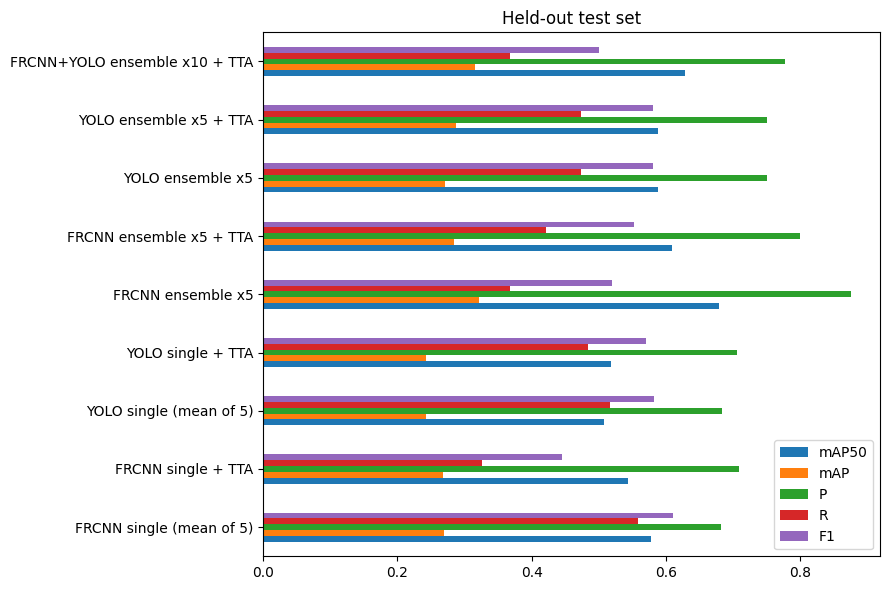

In [5]:
sz=CFGS[best_cfg]["imgsz"]
Fm=[]; 
for f in range(K):
    m=build_frcnn(); m.load_state_dict(torch.load(f"frcnn_f{f}.pt")); Fm.append(("f",m.eval(),0))
Ym=[("y",YOLO(f"/kaggle/working/runs/{best_cfg}_f{f}/weights/last.pt"),sz) for f in range(K)]

def score(res,thr): m50,m=mAP(res); P,R,F=prf(res,thr); return {"mAP50":m50,"mAP":m,"P":P,"R":R,"F1":F}
rows={}
def single(name,models,thr,tta):
    r=[score(infer([s],test_items,tta),thr) for s in models]; d=pd.DataFrame(r); rows[name]=d.mean().to_dict(); rows[name+" (std mAP50)"]={"mAP50":d.mAP50.std()}
def ens(name,models,thr,tta): rows[name]=score(infer(models,test_items,tta),thr)
single("FRCNN single (mean of 5)",Fm,thr_f,False); single("FRCNN single + TTA",Fm,thr_f,True)
single("YOLO single (mean of 5)",Ym,thr_y,False);   single("YOLO single + TTA",Ym,thr_y,True)
ens("FRCNN ensemble x5",Fm,thr_f,False);   ens("FRCNN ensemble x5 + TTA",Fm,thr_f,True)
ens("YOLO ensemble x5",Ym,thr_y,False);    ens("YOLO ensemble x5 + TTA",Ym,thr_y,True)
ens("FRCNN+YOLO ensemble x10 + TTA",Fm+Ym,(thr_f+thr_y)/2,True)
final=pd.DataFrame(rows).T.round(3); print(final.to_string()); final.to_csv("final_test_results.csv")
final.loc[[r for r in final.index if "std" not in r],["mAP50","mAP","P","R","F1"]].plot.barh(figsize=(9,6)); plt.title("Held-out test set"); plt.tight_layout(); plt.show()
json.dump({"single_class":SINGLE,"thr_frcnn":thr_f,"thr_yolo":thr_y,"yolo_cfg":best_cfg,"yolo_imgsz":sz},open("ensemble_config.json","w"))

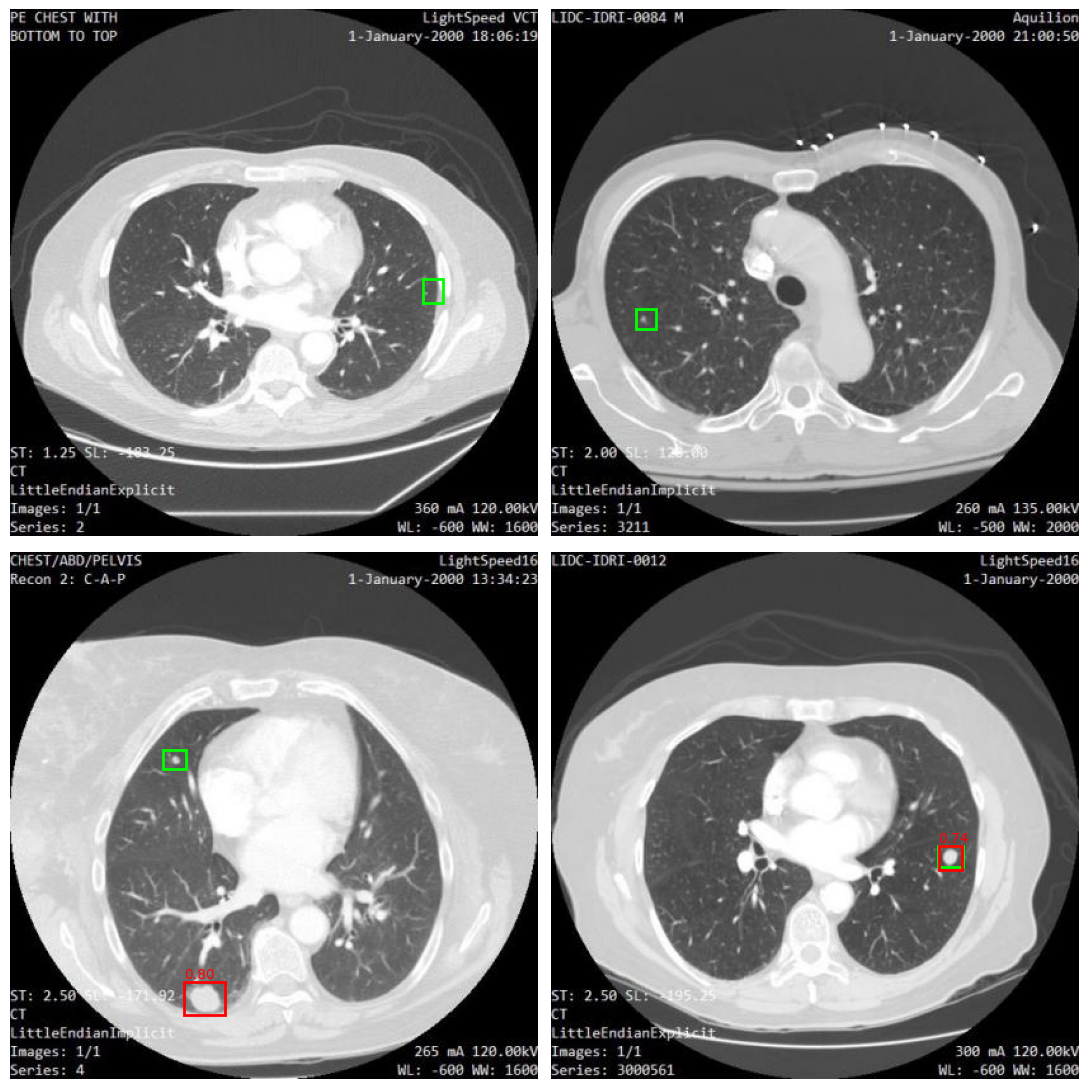

In [6]:
# visual check: best ensemble on 4 test images (green = ground truth, red = prediction + score)
specs=Fm+Ym; thr=(thr_f+thr_y)/2; res=infer(specs,test_items,True); fig,ax=plt.subplots(2,2,figsize=(11,11)); ax=ax.ravel()
for a,i in zip(ax,random.Random(1).sample(range(len(test_items)),4)):
    a.imshow(Image.open(test_items[i][0]).convert("RGB")); a.axis("off"); p,t=res[i]
    for b in t["boxes"]: a.add_patch(patches.Rectangle((b[0],b[1]),b[2]-b[0],b[3]-b[1],fill=False,ec="lime",lw=2))
    for b,s in zip(p["boxes"],p["scores"]):
        if s>=thr: a.add_patch(patches.Rectangle((b[0],b[1]),b[2]-b[0],b[3]-b[1],fill=False,ec="red",lw=2)); a.text(b[0],b[1]-3,f"{s:.2f}",color="red")
plt.tight_layout(); plt.show()

In [7]:
import os, shutil, glob
D="/kaggle/working/deliver"; os.makedirs(f"{D}/models",exist_ok=True); os.makedirs(f"{D}/yolo_baseline",exist_ok=True); os.makedirs(f"{D}/results",exist_ok=True)
for f in glob.glob("/kaggle/working/frcnn_f*.pt")+["/kaggle/working/ensemble_config.json"]: shutil.copy(f,f"{D}/models/")
for f in ["final_test_results.csv","yolo_sweep_cv.csv"]: shutil.copy(f"/kaggle/working/{f}",f"{D}/results/")
for i in range(5):
    s=f"/kaggle/working/runs/s640_f{i}"
    shutil.copy(f"{s}/weights/last.pt",f"{D}/yolo_baseline/s640_f{i}.pt")
    if i==0: shutil.copy(f"{s}/results.csv",f"{D}/yolo_baseline/s640_f0_results.csv")
shutil.make_archive("/kaggle/working/deliver","zip",D); print(os.path.getsize("/kaggle/working/deliver.zip")/1e6,"MB")

908.683297 MB
